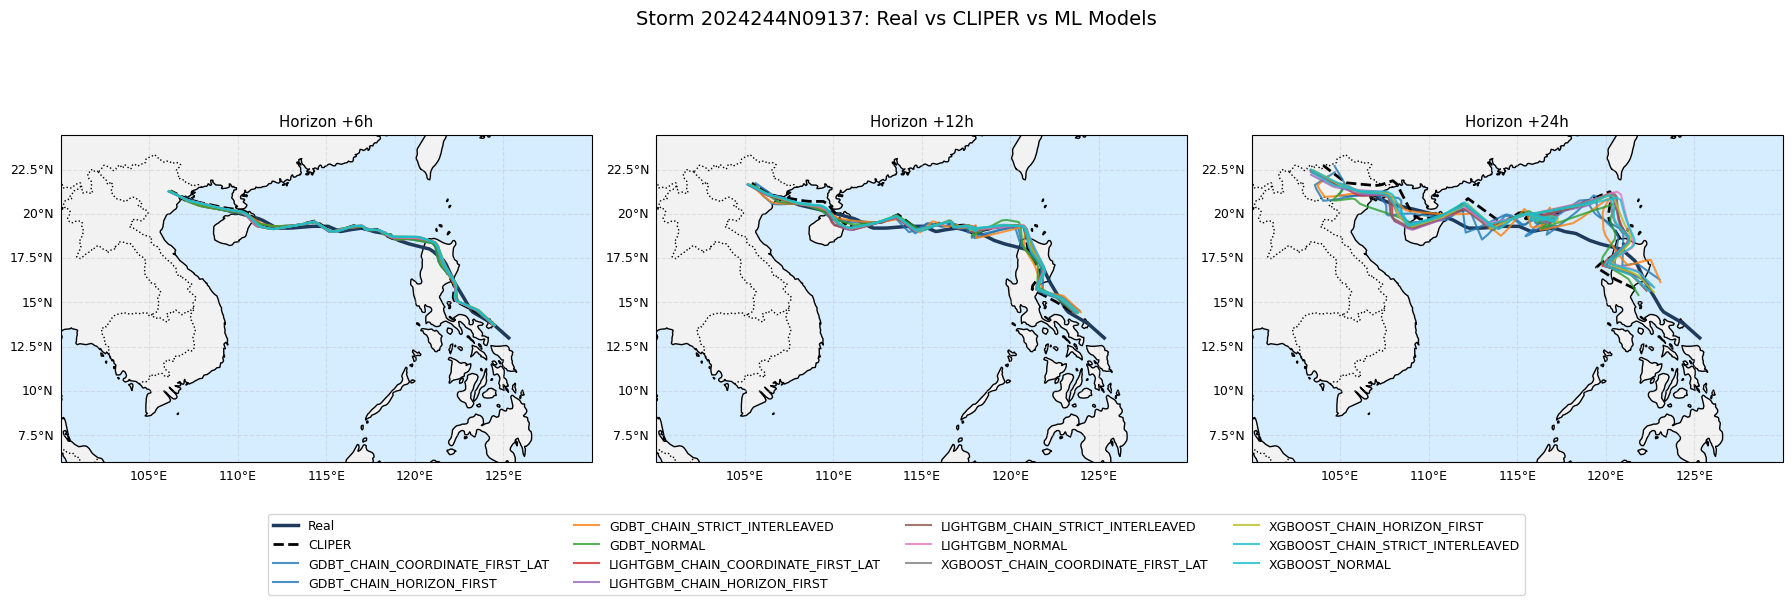

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

df = pd.read_csv("../experiments/detailed_trajectories_predictions.csv")

sid = "2024244N09137"
storm_df = df[df["SID"] == sid].copy()

storm_df["time"] = pd.to_datetime(
    storm_df["YEAR"].astype(str) + "-" +
    storm_df["MONTH"].astype(str) + "-" +
    storm_df["DAY"].astype(str) + " " +
    storm_df["HOUR"].astype(str) + ":00"
)

storm_df = storm_df.sort_values("time")

def smooth(x, y):
    if len(x) < 3:
        return x, y
    t = np.linspace(0, 1, len(x))
    t_new = np.linspace(0, 1, 100)
    return np.interp(t_new, t, x), np.interp(t_new, t, y)

real_df = storm_df.drop_duplicates(subset=["time"])
real_lon = real_df["BASE_LON"].values
real_lat = real_df["BASE_LAT"].values

real_lon_s, real_lat_s = smooth(real_lon, real_lat)

# ========================
# SETUP FIG
# ========================
horizons = ['+6h', '+12h', '+24h']

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

# Lấy tất cả model (trừ CLIPER)
ml_models = sorted([s for s in storm_df["Strategy"].unique() if "CLIPER" not in s])

colors = cm.tab10(np.linspace(0, 1, len(ml_models)))

# ========================
# LOOP THEO HORIZON
# ========================
for ax, horizon in zip(axes, horizons):

    # MAP
    ax.add_feature(cfeature.LAND, facecolor="#f2f2f2")
    ax.add_feature(cfeature.OCEAN, facecolor="#d6ecff")
    ax.add_feature(cfeature.COASTLINE, linewidth=1)
    ax.add_feature(cfeature.BORDERS, linestyle=":")

    ax.set_extent([100, 130, 6, 24])

    # GRID (CHỈ TRÁI + DƯỚI)
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = True
    gl.bottom_labels = True

    # ========================
    # REAL
    # ========================
    ax.plot(real_lon_s, real_lat_s,
            color='#1f3b5c',
            linewidth=2.5,
            label='Real')

    # ========================
    # CLIPER
    # ========================
    cliper_df = storm_df[
        (storm_df["Strategy"] == "CLIPER_BASELINE") &
        (storm_df["Horizon"] == horizon)
    ]

    if not cliper_df.empty:
        lon_s, lat_s = smooth(
            cliper_df["PRED_TARGET_LON"],
            cliper_df["PRED_TARGET_LAT"]
        )

        ax.plot(lon_s, lat_s,
                color='black',
                linestyle='--',
                linewidth=2,
                label='CLIPER')

    # ========================
    # ML MODELS
    # ========================
    for model, color in zip(ml_models, colors):

        model_df = storm_df[
            (storm_df["Strategy"] == model) &
            (storm_df["Horizon"] == horizon)
        ]

        if model_df.empty:
            continue

        lon_s, lat_s = smooth(
            model_df["PRED_TARGET_LON"],
            model_df["PRED_TARGET_LAT"]
        )

        ax.plot(lon_s, lat_s,
                color=color,
                linewidth=1.5,
                alpha=0.8,
                label=model)

    ax.set_title(f"Horizon {horizon}")

# ========================
# LEGEND (CHUNG)
# ========================
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4)

plt.suptitle(f"Storm {sid}: Real vs CLIPER vs ML Models", fontsize=14)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("../experiments/results/plots/compare_all_models.png", dpi=300)
plt.show()

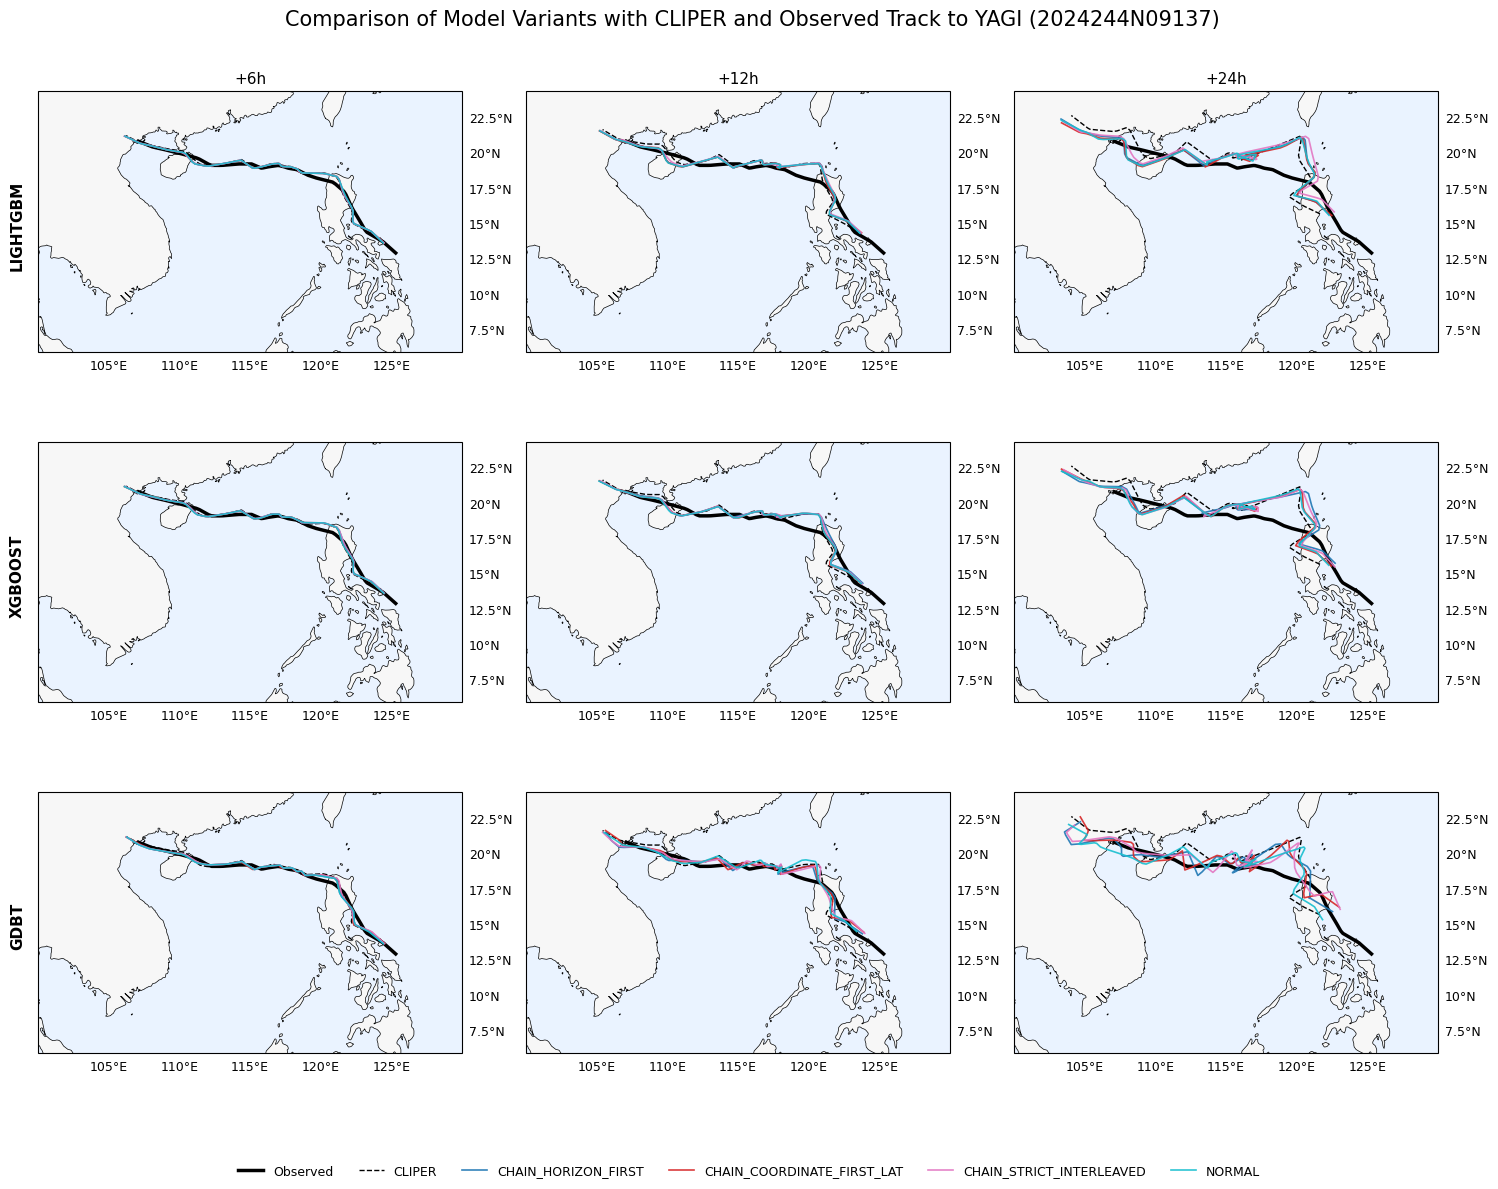

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

df = pd.read_csv("../experiments/detailed_trajectories_predictions.csv")

sid = "2024244N09137"
storm_df = df[df["SID"] == sid].copy()

storm_df["time"] = pd.to_datetime(
    storm_df["YEAR"].astype(str) + "-" +
    storm_df["MONTH"].astype(str) + "-" +
    storm_df["DAY"].astype(str) + " " +
    storm_df["HOUR"].astype(str) + ":00"
)

storm_df = storm_df.sort_values("time")

def smooth(x, y):
    if len(x) < 3:
        return x, y
    t = np.linspace(0, 1, len(x))
    t_new = np.linspace(0, 1, 100)
    return np.interp(t_new, t, x), np.interp(t_new, t, y)

real_df = storm_df.drop_duplicates(subset=["time"])
real_lon = real_df["BASE_LON"].values
real_lat = real_df["BASE_LAT"].values

real_lon_s, real_lat_s = smooth(real_lon, real_lat)

# ========================
# SETUP
# ========================
base_models = ["LIGHTGBM", "XGBOOST", "GDBT"]
horizons = ['+6h', '+12h', '+24h']

fig, axes = plt.subplots(
    len(base_models), len(horizons),
    figsize=(15, 12),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

# ========================
# STYLE
# ========================
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 9
})

# ========================
# LOOP
# ========================
for i, base in enumerate(base_models):
    for j, horizon in enumerate(horizons):

        ax = axes[i, j]

        # ================= MAP =================
        ax.add_feature(cfeature.LAND, facecolor="#f7f7f7")
        ax.add_feature(cfeature.OCEAN, facecolor="#eaf3ff")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

        ax.set_extent([100, 130, 6, 24])

        # GRID (minimal)
        gl = ax.gridlines(draw_labels=True, linewidth=0)
        gl.top_labels = False
        gl.left_labels = False

        # ================= REAL =================
        ax.plot(real_lon_s, real_lat_s,
                color='black',
                linewidth=2.5,
                label='Observed')

        # ================= CLIPER =================
        cliper_df = storm_df[
            (storm_df["Strategy"] == "CLIPER_BASELINE") &
            (storm_df["Horizon"] == horizon)
        ]

        if not cliper_df.empty:
            lon_s, lat_s = smooth(
                cliper_df["PRED_TARGET_LON"],
                cliper_df["PRED_TARGET_LAT"]
            )

            ax.plot(lon_s, lat_s,
                    color='black',
                    linestyle='--',
                    linewidth=1,
                    label='CLIPER')

        # ================= MODEL FAMILY =================
        sub_models = [
            s for s in storm_df["Strategy"].unique()
            if base in s
        ]

        colors = plt.cm.tab10(np.linspace(0, 1, len(sub_models)))

        for model, color in zip(sub_models, colors):

            model_df = storm_df[
                (storm_df["Strategy"] == model) &
                (storm_df["Horizon"] == horizon)
            ]

            if model_df.empty:
                continue

            lon_s, lat_s = smooth(
                model_df["PRED_TARGET_LON"],
                model_df["PRED_TARGET_LAT"]
            )

            ax.plot(lon_s, lat_s,
                    color=color,
                    linewidth=1.2,
                    alpha=0.9,
                    label=model.replace(base + "_", ""))

        # ================= LABELS =================
        if i == 0:
            ax.set_title(horizon, fontsize=11)

        if j == 0:
            ax.text(98, 15,
                    base,
                    rotation=90,
                    va='center',
                    fontsize=11,
                    weight='bold')

# ========================
# LEGEND (CHUNG)
# ========================
handles, labels = ax.get_legend_handles_labels()

fig.legend(handles, labels,
           loc='lower center',
           ncol=6,
           frameon=False)

# ========================
# FINAL
# ========================
plt.suptitle("Comparison of Model Variants with CLIPER and Observed Track to YAGI (2024244N09137)", fontsize=15)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig("../experiments/results/plots/final_paper.png", dpi=300)
plt.show()